# Preprocesamiento para clasificar la condición de egreso

El objetivo futuro es clasificar un egreso hospitalario como **Vivo** o **Muerto** usando los datos históricos de la hospitalización. Esta entrega parte del Parquet de 2023–2025, que el equipo ya normalizó. Aquí se seleccionan las variables, se revisan los faltantes, se asignan los tipos de datos y se guarda una base específica para el objetivo de clasificación.

Cada fila representa un egreso hospitalario. Se utilizan datos del episodio completo, como la duración de la estadía y el diagnóstico definitivo.

**Para ejecutar.** Coloca este notebook en la raíz del proyecto, selecciona el kernel del proyecto y ejecuta todas las celdas. Si lo abres desde otra carpeta, ajusta `ARCHIVO_BASE`. La salida `egresos_clasificacion_preparados.parquet` se guarda en la carpeta de ejecución.

## 1. Diccionario y justificación de la selección

| Columna | Tipo de dato | Qué representa y por qué se conserva |
| --- | --- | --- |
| `DIAG1_DESCRIPCION` | Categórico nominal, glosa | Describe el diagnóstico principal con el detalle del código completo del registro. Permite comparar la condición de egreso entre diagnósticos específicos usando una sola columna legible. |
| `GRUPO_EDAD` | Categórico, tramo con orden natural | Describe la edad al ingreso por intervalo. Permite comparar egresos entre etapas de la vida y respeta la granularidad de la fuente. En el archivo se mantiene como categoría con etiqueta. |
| `SEXO` | Categórico nominal | Identifica el sexo registrado. Permite examinar diferencias descriptivas entre grupos. |
| `REGION_RESIDENCIA` | Categórico nominal, código | Identifica la región de residencia y permite describir diferencias territoriales. El literal `NULL` representa «Extranjero». |
| `PREVISION` | Categórico nominal, código | Identifica el tipo de previsión. Aporta contexto sobre cobertura registrada en el episodio. |
| `PERTENENCIA_ESTABLECIMIENTO_SALU` | Categórico nominal | Identifica la pertenencia a la red de salud. Aporta contexto del establecimiento en el que se atendió el egreso. |
| `DIAS_ESTADA` | Cuantitativo discreto, entero | Es la duración total de la hospitalización. Se conserva el conteo para estudiar cómo cambia la proporción de fallecimientos según la estadía. |
| `FALLECIDO` | Categórica binaria | Es la condición de egreso que se buscará clasificar. Sus categorías son `Vivo` y `Muerto`. |
| `ANO_FUENTE` | Entero de procedencia | Identifica el año del archivo. Se conserva para una futura separación temporal y se excluye de las entradas. |

La selección reúne información clínica, demográfica, territorial y del establecimiento. La glosa se usa como representación única del diagnóstico. Su selección se basa en el propósito del análisis. El aporte predictivo de cada entrada se evaluará posteriormente.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import pandas as pd

ARCHIVO_BASE = Path("datos/procesados/egresos_2023_2025_base_comun.parquet")
ARCHIVO_SALIDA = Path("egresos_clasificacion_preparados.parquet")
CATEGORICAS = [
    "DIAG1_DESCRIPCION",
    "GRUPO_EDAD",
    "SEXO",
    "REGION_RESIDENCIA",
    "PREVISION",
    "PERTENENCIA_ESTABLECIMIENTO_SALU",
]
ENTRADAS = ["DIAS_ESTADA", *CATEGORICAS]
OBJETIVO = "CONDICION_EGRESO"

if not ARCHIVO_BASE.is_file():
    raise FileNotFoundError(f"Indica la ruta del Parquet en ARCHIVO_BASE. Busqué en {ARCHIVO_BASE.resolve()}")

base = pd.read_parquet(ARCHIVO_BASE, columns=["ANO_FUENTE", *ENTRADAS, OBJETIVO])
print(f"Egresos leídos: {len(base):,}")
display(base.dtypes.astype(str).rename("Tipo en la base común").to_frame())

Egresos leídos: 4,985,130


,Tipo en la base común
ANO_FUENTE,int16
DIAS_ESTADA,Int64
DIAG1_DESCRIPCION,string
GRUPO_EDAD,string
SEXO,string
REGION_RESIDENCIA,string
PREVISION,string
PERTENENCIA_ESTABLECIMIENTO_SALU,string
CONDICION_EGRESO,Int64


## 2. Preparación y tratamiento de los faltantes

Se convierte la glosa del diagnóstico y las demás variables categóricas al tipo `category`. Si el diccionario carece de una glosa exacta, se usa la etiqueta `SIN_DESCRIPCION`. En las otras variables categóricas, un valor realmente ausente se representa como `SIN_DATO`. Se conserva la etiqueta original cuando está disponible, incluyendo el literal `NULL` de región.

Los días de estadía siguen siendo enteros, incluidos los valores extremos. Se comprueba que sean válidos. La condición original se traduce a `Vivo` (código 1 en la fuente) y `Muerto` (código 2 en la fuente) y se guarda como `category`. Si aparece una etiqueta de egreso inválida o ausente, se contabiliza y se excluye de esta base supervisada.

In [2]:
etiquetas = base[OBJETIVO].map({1: "Vivo", 2: "Muerto"})
etiqueta_valida = etiquetas.notna()
print(f"Egresos excluidos por etiqueta ausente o inválida: {(~etiqueta_valida).sum():,}")

preparada = base.loc[etiqueta_valida, ["ANO_FUENTE", *ENTRADAS]].copy()
faltantes = preparada[ENTRADAS].isna().sum()

dias = preparada["DIAS_ESTADA"]
if dias.isna().any() or dias.lt(0).any():
    raise ValueError("Revisa los días de estadía ausentes o negativos antes de guardar.")
preparada["DIAS_ESTADA"] = dias.astype("int64")
preparada["FALLECIDO"] = etiquetas.loc[etiqueta_valida].astype("category")

for columna in CATEGORICAS:
    etiqueta_ausente = "SIN_DESCRIPCION" if columna == "DIAG1_DESCRIPCION" else "SIN_DATO"
    preparada[columna] = preparada[columna].fillna(etiqueta_ausente).astype("category")

resumen = pd.DataFrame({
    "Ausentes en la base común": faltantes,
    "Tipo preparado": preparada[ENTRADAS].dtypes.astype(str),
    "Valores distintos conservados": preparada[ENTRADAS].nunique(),
})
display(resumen)

Egresos excluidos por etiqueta ausente o inválida: 0


,Ausentes en la base común,Tipo preparado,Valores distintos conservados
DIAS_ESTADA,0,int64,1260
DIAG1_DESCRIPCION,527,category,7739
GRUPO_EDAD,371577,category,12
SEXO,371577,category,4
REGION_RESIDENCIA,371577,category,19
PREVISION,371577,category,8
PERTENENCIA_ESTABLECIMIENTO_SALU,371577,category,3


## 3. Ejemplo antes y después

Se muestran cinco registros de la fuente y sus valores preparados. Las glosas se leen igual después de la conversión. La diferencia está en su tipo interno de datos, que se ve en la tabla de la sección anterior. Los días mantienen su significado numérico.

In [3]:
indices = preparada.head(5).index
display(base.loc[indices, ["DIAS_ESTADA", "DIAG1_DESCRIPCION", "GRUPO_EDAD", OBJETIVO]])
display(preparada.loc[indices, ["DIAS_ESTADA", "DIAG1_DESCRIPCION", "GRUPO_EDAD", "FALLECIDO"]])

por_anio = (
    preparada["FALLECIDO"].eq("Muerto").groupby(preparada["ANO_FUENTE"])
    .agg(Egresos="size", Fallecidos="sum")
)
por_anio["Fallecidos (%)"] = (100 * (por_anio["Fallecidos"] / por_anio["Egresos"])).round(3)
display(por_anio)

,DIAS_ESTADA,DIAG1_DESCRIPCION,GRUPO_EDAD,CONDICION_EGRESO
0,7,"HEMANGIOMA, DE CUALQUIER SITIO",1 a 9,1
1,2,CUERPO EXTRAÑO EN EL ESOFAGO,1 a 9,1
2,1,OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,1 a 9,1
3,6,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,1 a 9,1
4,1,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,1 a 9,1


,DIAS_ESTADA,DIAG1_DESCRIPCION,GRUPO_EDAD,FALLECIDO
0,7,"HEMANGIOMA, DE CUALQUIER SITIO",1 a 9,Vivo
1,2,CUERPO EXTRAÑO EN EL ESOFAGO,1 a 9,Vivo
2,1,OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,1 a 9,Vivo
3,6,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,1 a 9,Vivo
4,1,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,1 a 9,Vivo


,Egresos,Fallecidos,Fallecidos (%)
ANO_FUENTE,,,
2023,1612267,37735,2.340
2024,1667349,39599,2.375
2025,1705514,40051,2.348


### Primeras y últimas filas de la base preparada

`head(5)` muestra las primeras cinco filas y `tail(5)` las últimas cinco, en el orden del archivo. En ambas tablas se ven las nueve columnas, incluida la glosa del diagnóstico y la etiqueta `Vivo` o `Muerto`.

In [4]:
print("Primeras cinco filas")
print(preparada.head(5).to_string())
print()
print("Últimas cinco filas")
print(preparada.tail(5).to_string())

Primeras cinco filas
   ANO_FUENTE  DIAS_ESTADA                                DIAG1_DESCRIPCION GRUPO_EDAD    SEXO REGION_RESIDENCIA PREVISION                                PERTENENCIA_ESTABLECIMIENTO_SALU FALLECIDO
0        2023            7                   HEMANGIOMA, DE CUALQUIER SITIO      1 a 9  HOMBRE                01         1  Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS      Vivo
1        2023            2                     CUERPO EXTRAÑO EN EL ESOFAGO      1 a 9  HOMBRE                01         1  Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS      Vivo
2        2023            1  OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS      1 a 9  HOMBRE                01         1  Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS      Vivo
3        2023            6     APENDICITIS AGUDA CON PERITONITIS LOCALIZADA      1 a 9  HOMBRE                01         1  Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS     

## 4. Descripción de la base y exploración histórica

La base conserva una fila por egreso y contiene los años 2023–2025. El resumen por año muestra el tamaño de cada cohorte y el porcentaje de la clase fallecido. La tabla de calidad registra cuántos valores faltaban antes de la preparación y cuántos valores distintos tiene cada entrada preparada.

En la duración de la estadía se reportan mínimo, mediana, cuartiles, percentil 95 y máximo. Para el diagnóstico se muestran las diez glosas más frecuentes y el porcentaje de fallecimientos por tramo de estadía dentro de los tres diagnósticos más frecuentes. Los tramos sirven para la exploración. La columna original mantiene el número de días.

In [5]:
display(preparada["DIAS_ESTADA"].describe(percentiles=[0.25, 0.50, 0.75, 0.95]).to_frame("Días de estadía").round(2))

def resumir_egresos(datos, grupos):
    tabla = (
        datos.assign(es_muerto=datos["FALLECIDO"].eq("Muerto"))
        .groupby(grupos, observed=True)["es_muerto"]
        .agg(Egresos="size", Fallecidos="sum")
    )
    tabla["Fallecidos (%)"] = (100 * (tabla["Fallecidos"] / tabla["Egresos"])).round(2)
    return tabla


diagnosticos = resumir_egresos(preparada, "DIAG1_DESCRIPCION")
frecuentes = diagnosticos.drop(index="SIN_DESCRIPCION", errors="ignore").nlargest(10, "Egresos")
display(frecuentes)

es_frecuente = preparada["DIAG1_DESCRIPCION"].isin(frecuentes.head(3).index)
exploracion = preparada.loc[es_frecuente, ["DIAG1_DESCRIPCION", "DIAS_ESTADA", "FALLECIDO"]].copy()
exploracion["Tramo de estadía"] = pd.cut(
    exploracion["DIAS_ESTADA"],
    bins=[0, 1, 3, 7, 14, 30, float("inf")],
    labels=["0–1 día", "2–3 días", "4–7 días", "8–14 días", "15–30 días", "31 días o más"],
    include_lowest=True,
)
display(resumir_egresos(exploracion, ["DIAG1_DESCRIPCION", "Tramo de estadía"]))

,Días de estadía
count,4985130.00
mean,6.13
std,45.12
min,1.00
25%,1.00
50%,2.00
75%,6.00
95%,21.00
max,22239.00


,Egresos,Fallecidos,Fallecidos (%)
DIAG1_DESCRIPCION,,,
"PARTO UNICO ESPONTANEO, PRESENTACION CEFALICA DE VERTICE",71868,1,0.00
OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,65699,17,0.03
CALCULO DE LA VESICULA BILIAR SIN COLECISTITIS,61981,31,0.05
PARTO POR CESAREA ELECTIVA,60307,1,0.00
"NEUMONIA, NO ESPECIFICADA",55999,5897,10.53
"PARTO POR CESAREA, SIN OTRA ESPECIFICACION",55501,3,0.01
"INFECCION DE VÍAS URINARIAS, SITIO NO ESPECIFICADO",47406,1771,3.74
"PARTO UNICO ESPONTANEO, SIN OTRA ESPECIFICACION",45517,0,0.00
OTRAS COLELITIASIS,45187,13,0.03


Egresos  Fallecidos  Fallecidos (%)
DIAG1_DESCRIPCION                                        Tramo de estadía                                     
CALCULO DE LA VESICULA BILIAR SIN COLECISTITIS           0–1 día             43406           8            0.02
                                                         2–3 días            10930           2            0.02
                                                         4–7 días             3985           4            0.10
                                                         8–14 días            2632           9            0.34
                                                         15–30 días            910           6            0.66
                                                         31 días o más         118           2            1.69
OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS          0–1 día             40506           4            0.01
                                                         2–3 días            18118           2            0.01
                                                         4–7 días             5674           5            0.09
                                                         8–14 días            1096           3            0.27
                                                         15–30 días            246           1            0.41
                                                         31 días o más          59           2            3.39
PARTO UNICO ESPONTANEO, PRESENTACION CEFALICA DE VERTICE 0–1 día              1826           0            0.00
                                                         2–3 días            63136           1            0.00
                                                         4–7 días             6545           0            0.00
                                                         8–14 días             327           0            0.00
                                                         15–30 días             28           0            0.00
                                                         31 días o más           6           0            0.00

## 5. Correlación y asociación con la condición de egreso

Se usa `corr(method="pearson")` para **días de estadía y fallecimiento**. Para calcularla, se representa temporalmente `Vivo` como 0 y `Muerto` como 1. La correlación resultante equivale a la correlación punto-biserial. La matriz muestra el sentido y la fuerza de la relación lineal.

Para las **variables categóricas** se calcula la **V de Cramér corregida** a partir de tablas de conteos con la condición de egreso. Los códigos de previsión y región son etiquetas, por lo que asignarles números para calcular Pearson introduciría un orden artificial. La V varía de 0 a 1 y mide la intensidad de la asociación sin indicar dirección. El cálculo aplica la [corrección de Bergsma](https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf).

El segundo mapa de calor muestra el **porcentaje de egresos fallecidos**, junto con el número de egresos de cada grupo, al cruzar diagnóstico y días de estadía. Las medidas describen estos registros históricos. La contribución a un modelo se verificará en la etapa de entrenamiento y evaluación.

In [6]:
import numpy as np

datos_correlacion = preparada[["DIAS_ESTADA"]].assign(
    FALLECIDO=preparada["FALLECIDO"].eq("Muerto").astype("uint8")
)
correlacion = datos_correlacion.corr(method="pearson")
display(correlacion.round(3))


def v_cramer_corregida(tabla):
    observados = tabla.to_numpy(dtype=float)
    n = observados.sum()
    filas, columnas = observados.shape
    if min(filas, columnas) < 2 or n <= 1:
        return np.nan

    esperados = np.outer(observados.sum(axis=1), observados.sum(axis=0)) / n
    phi_cuadrado = (((observados - esperados) ** 2) / esperados).sum() / n
    phi_corregido = max(0, phi_cuadrado - (filas - 1) * (columnas - 1) / (n - 1))
    filas_corregidas = filas - (filas - 1) ** 2 / (n - 1)
    columnas_corregidas = columnas - (columnas - 1) ** 2 / (n - 1)
    denominador = min(filas_corregidas - 1, columnas_corregidas - 1)
    return np.sqrt(phi_corregido / denominador) if denominador > 0 else np.nan


asociaciones = {}
niveles = {}
for columna in CATEGORICAS:
    conteos = pd.crosstab(preparada[columna], preparada["FALLECIDO"])
    asociaciones[columna] = v_cramer_corregida(conteos)
    niveles[columna] = len(conteos)

tabla_asociacion = pd.DataFrame({
    "Categorías observadas": pd.Series(niveles),
    "V de Cramér corregida": pd.Series(asociaciones),
}).sort_values("V de Cramér corregida", ascending=False)
display(tabla_asociacion.round(3))

,DIAS_ESTADA,FALLECIDO
DIAS_ESTADA,1.000,0.042
FALLECIDO,0.042,1.000


,Categorías observadas,V de Cramér corregida
DIAG1_DESCRIPCION,7739,0.348
GRUPO_EDAD,12,0.181
PERTENENCIA_ESTABLECIMIENTO_SALU,3,0.071
PREVISION,8,0.050
SEXO,4,0.032
REGION_RESIDENCIA,19,0.020


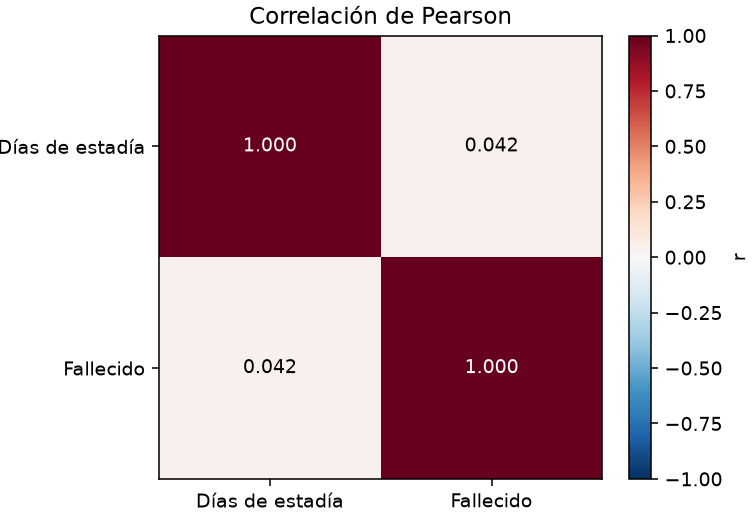

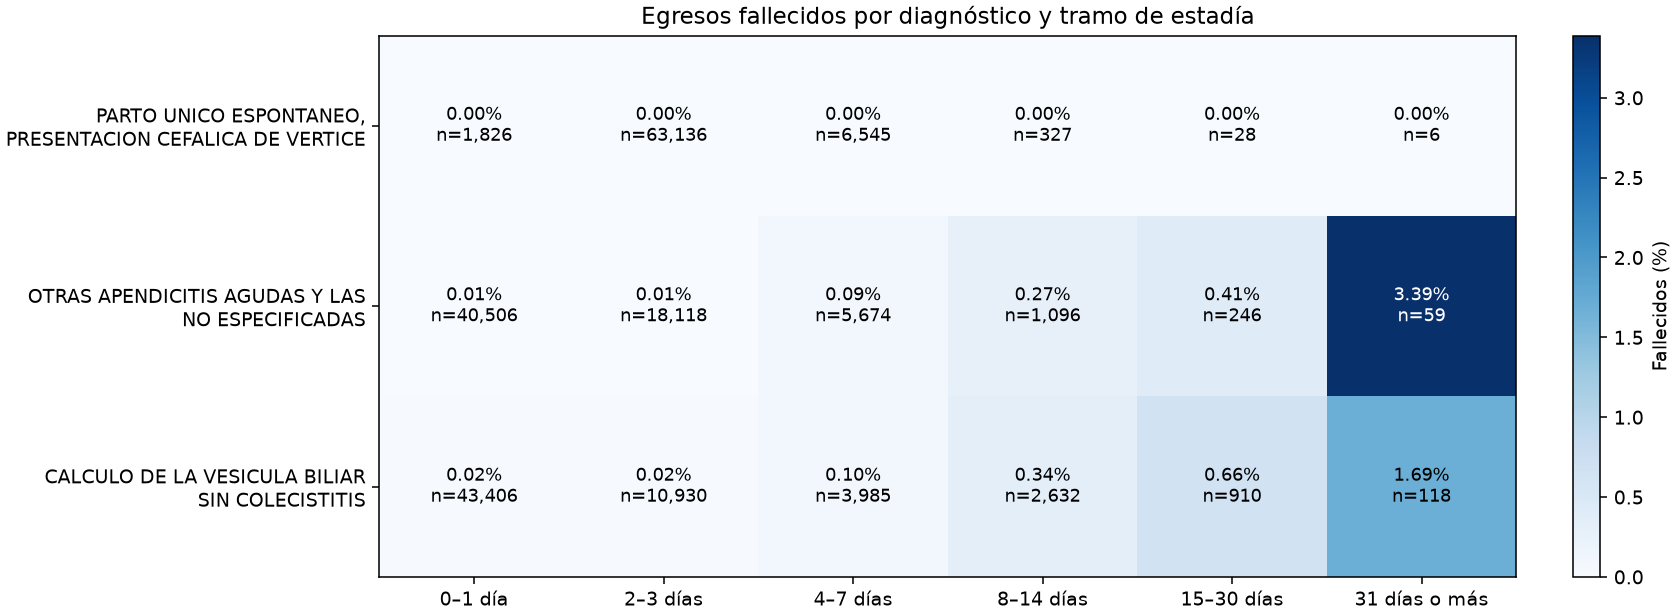

In [7]:
from textwrap import fill
import matplotlib.pyplot as plt

fig, eje = plt.subplots(figsize=(5.4, 3.7), layout="constrained")
imagen = eje.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_title("Correlación de Pearson")
eje.set_xticks(range(2), ["Días de estadía", "Fallecido"])
eje.set_yticks(range(2), ["Días de estadía", "Fallecido"])
for fila in range(2):
    for columna in range(2):
        valor = correlacion.iloc[fila, columna]
        eje.text(columna, fila, f"{valor:.3f}", ha="center", va="center",
                 color="white" if abs(valor) > 0.6 else "black")
fig.colorbar(imagen, ax=eje, label="r")
display(fig)
plt.close(fig)

tramos = exploracion["Tramo de estadía"].cat.categories
cruce = resumir_egresos(exploracion, ["DIAG1_DESCRIPCION", "Tramo de estadía"])
orden_diagnosticos = frecuentes.head(3).index
tasas = cruce["Fallecidos (%)"].unstack().reindex(index=orden_diagnosticos, columns=tramos)
totales = cruce["Egresos"].unstack().reindex(index=orden_diagnosticos, columns=tramos)

fig, eje = plt.subplots(figsize=(12, 4.4), layout="constrained")
imagen = eje.imshow(tasas.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0)
eje.set_title("Egresos fallecidos por diagnóstico y tramo de estadía")
eje.set_xticks(range(len(tramos)), tramos)
eje.set_yticks(range(len(tasas)), [fill(glosa, 32) for glosa in tasas.index])
for fila, columna in np.ndindex(tasas.shape):
    tasa = tasas.iloc[fila, columna]
    total = totales.iloc[fila, columna]
    texto = "Sin egresos" if pd.isna(total) else f"{tasa:.2f}%\nn={int(total):,}"
    color = "white" if pd.notna(tasa) and imagen.norm(tasa) > 0.58 else "black"
    eje.text(columna, fila, texto, ha="center", va="center", color=color, fontsize=9)
fig.colorbar(imagen, ax=eje, label="Fallecidos (%)")
display(fig)
plt.close(fig)

**Interpretación.** La correlación lineal global entre la duración de la estadía y el fallecimiento es positiva y débil (`r = 0,042`). Entre las variables categóricas, la mayor asociación observada con la condición de egreso corresponde a la glosa del diagnóstico (`V = 0,348`), seguida por el grupo de edad (`V = 0,181`).

En el mapa de diagnóstico, para «Otras apendicitis agudas y las no especificadas», el porcentaje de egresos fallecidos fue de 0,09 % en estadías de 4–7 días (5 de 5.674) y de 3,39 % en estadías de 31 días o más (2 de 59). Leer el porcentaje junto con el número de egresos permite reconocer los grupos pequeños. Los porcentajes se muestran redondeados a dos decimales.

## 6. Guardar y verificar la base

Se guarda el Parquet preparado y se vuelve a leer para comprobar la cantidad de filas, las columnas, los tipos y los valores. La entrega termina con esta base y sus siete variables de entrada. La separación para entrenamiento y prueba y las transformaciones que dependan del algoritmo se harán en la siguiente etapa.

In [8]:
assert len(preparada) == int(etiqueta_valida.sum())
assert preparada.columns.tolist() == ["ANO_FUENTE", *ENTRADAS, "FALLECIDO"]
assert set(preparada["FALLECIDO"].unique()) == {"Vivo", "Muerto"}
columnas_categoricas = [*CATEGORICAS, "FALLECIDO"]
assert all(isinstance(preparada[columna].dtype, pd.CategoricalDtype) for columna in columnas_categoricas)
assert not preparada[ENTRADAS].isna().any().any()

with TemporaryDirectory(dir=ARCHIVO_SALIDA.parent) as carpeta_temporal:
    provisional = Path(carpeta_temporal) / ARCHIVO_SALIDA.name
    preparada.to_parquet(provisional, index=False)
    comprobacion = pd.read_parquet(provisional)
    assert all(isinstance(comprobacion[columna].dtype, pd.CategoricalDtype) for columna in columnas_categoricas)
    tipos_comparacion = {columna: "string" for columna in columnas_categoricas}
    pd.testing.assert_frame_equal(
        comprobacion.astype(tipos_comparacion),
        preparada.reset_index(drop=True).astype(tipos_comparacion),
    )
    provisional.replace(ARCHIVO_SALIDA)

print(f"Base guardada: {ARCHIVO_SALIDA.name}")
print(f"Egresos: {len(preparada):,} | Entradas: {len(ENTRADAS)} | Columnas totales: {preparada.shape[1]}")
display(comprobacion.dtypes.astype(str).rename("Tipo al volver a abrir el Parquet").to_frame())

Base guardada: egresos_clasificacion_preparados.parquet
Egresos: 4,985,130 | Entradas: 7 | Columnas totales: 9


,Tipo al volver a abrir el Parquet
ANO_FUENTE,int16
DIAS_ESTADA,int64
DIAG1_DESCRIPCION,category
GRUPO_EDAD,category
SEXO,category
REGION_RESIDENCIA,category
PREVISION,category
PERTENENCIA_ESTABLECIMIENTO_SALU,category
FALLECIDO,category
